# NAFLD / MASLD Optimized Model Development

**Dataset:** NHANES 2017–2018  
**Objective:** Optimize and evaluate models for an operational CAP-defined hepatic steatosis plus cardiometabolic-risk classification.

> **Important target limitation:** This notebook reproduces the existing operational target from the baseline notebook. It is not a confirmed clinical MASLD diagnosis. CAP threshold, simplified cardiometabolic indicators and approximate alcohol eligibility introduce uncertainty. NHANES survey weights are not used, so results are not nationally representative.

## Workflow
1. Load the NHANES 2017–2018 XPT datasets.
2. Recreate the adult liver-elastography cohort.
3. Construct cardiometabolic indicators and the operational MASLD label.
4. Create a stratified hold-out test set.
5. Establish baseline pipelines.
6. Tune Logistic Regression, Random Forest and XGBoost using training-only cross-validation.
7. Compare feature sets, including a demographic-only experiment without liver stiffness.
8. Select a threshold using training-only out-of-fold predictions.
9. Evaluate on the untouched test set.
10. Assess probability calibration and save complete pipelines.



## Stage 1: Setup

In [2]:
# ------------------ Stage 1: Setup ------------------

%pip install -q pandas numpy matplotlib seaborn scikit-learn scipy xgboost shap

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    average_precision_score, brier_score_loss
)

RANDOM_STATE = 42
N_SPLITS = 5

print("Setup complete.")

Setup complete.


## Stage 2: Load NHANES datasets

In [3]:
# ------------------ Stage 2: Load NHANES XPT Files ------------------

uploaded = files.upload()
datasets = {}

for filename in uploaded:
    if filename.lower().endswith(".xpt"):
        datasets[filename.rsplit(".", 1)[0]] = pd.read_sas(
            filename, format="xport"
        )

required = [
    "DEMO_J", "LUX_J", "BMX_J", "DIQ_J", "BPQ_J", "BPX_J",
    "ALQ_J", "GHB_J", "GLU_J", "HDL_J", "TRIGLY_J"
]
missing_files = [name for name in required if name not in datasets]

if missing_files:
    raise ValueError(
        f"Missing required files: {missing_files}. "
        "Upload all required NHANES 2017–2018 XPT files."
    )

for name in required:
    print(f"{name}: {datasets[name].shape}")

Saving ALQ_J.XPT to ALQ_J.XPT
Saving BMX_J.XPT to BMX_J.XPT
Saving BPQ_J.xpt to BPQ_J.xpt
Saving BPX_J.xpt to BPX_J.xpt
Saving DEMO_J.XPT to DEMO_J.XPT
Saving DIQ_J.XPT to DIQ_J.XPT
Saving GHB_J.xpt to GHB_J.xpt
Saving GLU_J.xpt to GLU_J.xpt
Saving HDL_J.xpt to HDL_J.xpt
Saving LUX_J.XPT to LUX_J.XPT
Saving MCQ_J.XPT to MCQ_J.XPT
Saving TRIGLY_J.xpt to TRIGLY_J.xpt
DEMO_J: (9254, 46)
LUX_J: (6401, 14)
BMX_J: (8704, 21)
DIQ_J: (8897, 54)
BPQ_J: (6161, 11)
BPX_J: (8704, 21)
ALQ_J: (5533, 10)
GHB_J: (6401, 2)
GLU_J: (3036, 4)
HDL_J: (7435, 3)
TRIGLY_J: (3036, 10)


## Stage 3: Recreate adult liver-elastography cohort

In [4]:
# ------------------ Stage 3: Cohort Construction ------------------

demo = datasets["DEMO_J"].copy()
lux = datasets["LUX_J"].copy()

eligible = demo.merge(lux, on="SEQN", how="inner")
eligible = eligible[eligible["RIDAGEYR"] >= 20].copy()

# Complete liver elastography exam and valid CAP measurement.
eligible = eligible[
    (eligible["LUAXSTAT"] == 1) &
    eligible["LUXCAPM"].notna()
].copy()

eligible["steatosis_flag"] = (
    eligible["LUXCAPM"] >= 302
).astype(int)

print("Adult complete-exam cohort:", eligible.shape)
print("\nCAP summary:")
display(eligible["LUXCAPM"].describe())

print("\nSteatosis flag counts:")
print(eligible["steatosis_flag"].value_counts())

assert eligible["SEQN"].is_unique, "Duplicate participant IDs found."

Adult complete-exam cohort: (4509, 60)

CAP summary:


,LUXCAPM
count,4509.000000
mean,265.182524
std,62.327396
min,100.000000
25%,219.000000
50%,265.000000
75%,309.000000
max,400.000000



Steatosis flag counts:
steatosis_flag
0    3222
1    1287
Name: count, dtype: int64


## Stage 4: Merge metabolic and questionnaire datasets

In [5]:
# ------------------ Stage 4: Merge Additional NHANES Data ------------------

masld_data = eligible.copy()

merge_names = [
    "BMX_J", "DIQ_J", "BPQ_J", "BPX_J", "ALQ_J",
    "GHB_J", "GLU_J", "HDL_J", "TRIGLY_J"
]

for name in merge_names:
    masld_data = masld_data.merge(
        datasets[name], on="SEQN", how="left",
        suffixes=("", "_duplicate")
    )

# Remove duplicate columns created by repeated shared fields if identical.
duplicate_cols = [c for c in masld_data.columns if c.endswith("_duplicate")]
for col in duplicate_cols:
    original = col.replace("_duplicate", "")
    if original in masld_data.columns:
        same = masld_data[original].equals(masld_data[col])
        if same:
            masld_data.drop(columns=col, inplace=True)

# Average available blood pressure readings.
systolic_cols = [c for c in ["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"] if c in masld_data.columns]
diastolic_cols = [c for c in ["BPXDI1", "BPXDI2", "BPXDI3", "BPXDI4"] if c in masld_data.columns]

masld_data["mean_systolic"] = masld_data[systolic_cols].mean(axis=1)
masld_data["mean_diastolic"] = masld_data[diastolic_cols].mean(axis=1)

print("Merged cohort shape:", masld_data.shape)
print("Duplicate SEQN:", masld_data["SEQN"].duplicated().sum())
assert masld_data["SEQN"].is_unique

Merged cohort shape: (4509, 188)
Duplicate SEQN: 0


## Stage 5: Construct cardiometabolic risk indicators

In [6]:
# ------------------ Stage 5: Cardiometabolic Risk Indicators ------------------

# BMI risk: operational thresholds used in the baseline workflow.
asian = masld_data["RIDRETH3"] == 6
masld_data["bmi_risk"] = np.where(
    masld_data["BMXBMI"].notna(),
    (masld_data["BMXBMI"] >= np.where(asian, 23, 25)).astype(int),
    np.nan
)

# Waist risk: operational thresholds used in the baseline workflow.
male = masld_data["RIAGENDR"] == 1
female = masld_data["RIAGENDR"] == 2
waist_cutoff = np.where(male, 94, np.where(female, 80, np.nan))
masld_data["waist_risk"] = np.where(
    masld_data["BMXWAIST"].notna() & pd.notna(waist_cutoff),
    (masld_data["BMXWAIST"] >= waist_cutoff).astype(int),
    np.nan
)

# Glycemic risk: HbA1c >= 5.7, fasting glucose >= 100, or
# self-reported diabetes/borderline response.
glycemic_positive = (
    (masld_data["LBXGH"] >= 5.7) |
    (masld_data["LBXGLU"] >= 100) |
    (masld_data["DIQ010"].isin([1, 3]))
)
glycemic_known = (
    masld_data["LBXGH"].notna() |
    masld_data["LBXGLU"].notna() |
    masld_data["DIQ010"].notna()
)
masld_data["glycemic_risk"] = np.where(
    glycemic_positive, 1,
    np.where(glycemic_known, 0, np.nan)
)

# Blood pressure risk: elevated mean BP or current antihypertensive medication.
bp_positive = (
    (masld_data["mean_systolic"] >= 130) |
    (masld_data["mean_diastolic"] >= 85) |
    (masld_data["BPQ050A"] == 1)
)
bp_known = (
    masld_data["mean_systolic"].notna() |
    masld_data["mean_diastolic"].notna() |
    masld_data["BPQ050A"].notna()
)
masld_data["bp_risk"] = np.where(
    bp_positive, 1,
    np.where(bp_known, 0, np.nan)
)

masld_data["triglyceride_risk"] = np.where(
    masld_data["LBXTR"].notna(),
    (masld_data["LBXTR"] >= 150).astype(int),
    np.nan
)

hdl_cutoff = np.where(male, 40, np.where(female, 50, np.nan))
masld_data["hdl_risk"] = np.where(
    masld_data["LBDHDD"].notna() & pd.notna(hdl_cutoff),
    (masld_data["LBDHDD"] <= hdl_cutoff).astype(int),
    np.nan
)

risk_cols = [
    "bmi_risk", "waist_risk", "glycemic_risk",
    "bp_risk", "triglyceride_risk", "hdl_risk"
]

risk_summary = []
for col in risk_cols:
    counts = masld_data[col].value_counts(dropna=False)
    risk_summary.append({
        "Indicator": col,
        "Present": int((masld_data[col] == 1).sum()),
        "Absent": int((masld_data[col] == 0).sum()),
        "Missing": int(masld_data[col].isna().sum())
    })

display(pd.DataFrame(risk_summary))

,Indicator,Present,Absent,Missing
0,bmi_risk,3407,1064,38
1,waist_risk,3360,984,165
2,glycemic_risk,2576,1933,0
3,bp_risk,2276,2111,122
4,triglyceride_risk,431,1693,2385
5,hdl_risk,1378,2909,222


## Stage 6: Approximate alcohol eligibility and operational target

In [7]:
# ------------------ Stage 6: Alcohol Eligibility and Target ------------------

# Approximate weekly frequency mapping used in the baseline notebook.
# This is a coarse estimate from categorical questionnaire responses,
# not a clinically precise alcohol exposure measure.
frequency_per_week = {
    0: 0,
    1: 7,
    2: 6,
    3: 3.5,
    4: 2,
    5: 1,
    6: 2.5 / 4.345,
    7: 1 / 4.345,
    8: 9 / 52,
    9: 4.5 / 52,
    10: 1.5 / 52
}

alq_freq = masld_data["ALQ121"].replace(
    [77, 99, 777, 999, 5.397605e-79], np.nan
)
alq_drinks = masld_data["ALQ130"].replace(
    [77, 99, 777, 999, 5.397605e-79], np.nan
)

frequency = alq_freq.map(frequency_per_week)
frequency = frequency.where(alq_freq != 0, 0)
weekly_drinks = frequency * alq_drinks
masld_data["alcohol_g_week"] = weekly_drinks * 14

# Approximate eligibility thresholds from the baseline workflow.
alcohol_limit = np.where(male, 210, np.where(female, 140, np.nan))
masld_data["alcohol_eligible"] = np.where(
    masld_data["alcohol_g_week"].notna() & pd.notna(alcohol_limit),
    (masld_data["alcohol_g_week"] < alcohol_limit).astype(int),
    np.nan
)

risk_present = (masld_data[risk_cols] == 1).any(axis=1)
risk_absent = (masld_data[risk_cols] == 0).all(axis=1)
masld_data["metabolic_risk"] = np.select(
    [risk_present, risk_absent], [1, 0], default=np.nan
)

# Operational target: 0 for no CAP-defined steatosis among alcohol-eligible
# participants; 1 for steatosis + at least one cardiometabolic risk factor
# among alcohol-eligible participants.
masld_data["MASLD"] = np.nan

eligible_alcohol = masld_data["alcohol_eligible"] == 1
no_steatosis = masld_data["steatosis_flag"] == 0
has_steatosis_and_risk = (
    (masld_data["steatosis_flag"] == 1) &
    (masld_data["metabolic_risk"] == 1)
)

masld_data.loc[eligible_alcohol & no_steatosis, "MASLD"] = 0
masld_data.loc[
    eligible_alcohol & has_steatosis_and_risk, "MASLD"
] = 1

model_data = masld_data[masld_data["MASLD"].notna()].copy()
model_data["MASLD"] = model_data["MASLD"].astype(int)

print("Labelled cohort:", model_data.shape)
print("\nOperational target counts:")
print(model_data["MASLD"].value_counts())
print("\nTarget proportions:")
print(model_data["MASLD"].value_counts(normalize=True).round(4))
print("\nExcluded/unlabelled participants:", masld_data["MASLD"].isna().sum())

Labelled cohort: (2694, 198)

Operational target counts:
MASLD
0    1943
1     751
Name: count, dtype: int64

Target proportions:
MASLD
0    0.7212
1    0.2788
Name: proportion, dtype: float64

Excluded/unlabelled participants: 1815


## Stage 7: Define predictors and prevent target leakage

The baseline model used age, sex, race/ethnicity and liver stiffness. CAP and variables directly used to construct the target are excluded. We will compare the full four-feature set against a demographic-only set without `LUXSMED`, because stiffness is measured during the same elastography examination as CAP and may act as a same-exam proxy.

In [8]:
# ------------------ Stage 7: Feature Selection ------------------

selected_features = ["RIDAGEYR", "RIAGENDR", "RIDRETH3", "LUXSMED"]

X = model_data[selected_features].copy()
y = model_data["MASLD"].astype(int).copy()

print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts())
print("\nMissing values:")
print(X.isna().sum())

assert "LUXCAPM" not in X.columns
assert "steatosis_flag" not in X.columns
assert "metabolic_risk" not in X.columns
assert X.index.equals(y.index)

Feature matrix: (2694, 4)
Target distribution:
MASLD
0    1943
1     751
Name: count, dtype: int64

Missing values:
RIDAGEYR    0
RIAGENDR    0
RIDRETH3    0
LUXSMED     0
dtype: int64


## Stage 8: Stratified hold-out split

In [9]:
# ------------------ Stage 8: Train-Test Split ------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).round(4))
print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).round(4))

Training shape: (2155, 4)
Testing shape: (539, 4)

Training proportions:
MASLD
0    0.7211
1    0.2789
Name: proportion, dtype: float64

Testing proportions:
MASLD
0    0.7217
1    0.2783
Name: proportion, dtype: float64


## Stage 9: Preprocessing and baseline pipelines

In [10]:
# ------------------ Stage 9: Preprocessing and Models ------------------

numeric_features = ["RIDAGEYR", "LUXSMED"]
categorical_features = ["RIAGENDR", "RIDRETH3"]

def make_preprocessor(feature_frame):
    numeric = [c for c in numeric_features if c in feature_frame.columns]
    categorical = [c for c in categorical_features if c in feature_frame.columns]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric),
        ("cat", categorical_pipe, categorical)
    ])

def make_pipeline(model, feature_frame):
    return Pipeline([
        ("preprocessor", make_preprocessor(feature_frame)),
        ("classifier", model)
    ])

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("XGBoost is not installed. Run !pip install xgboost and rerun this cell.")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced",
        solver="liblinear", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

if HAS_XGBOOST:
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE,
        n_jobs=-1
    )

baseline_pipelines = {
    name: make_pipeline(model, X_train)
    for name, model in models.items()
}

print("Prepared models:", list(baseline_pipelines))

Prepared models: ['Logistic Regression', 'Random Forest', 'XGBoost']


## Stage 10: Baseline evaluation

In [11]:
# ------------------ Stage 10: Baseline Evaluation ------------------

def calculate_metrics(y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Brier": brier_score_loss(y_true, probabilities)
    }

baseline_rows = []
for name, pipe in baseline_pipelines.items():
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    baseline_rows.append({
        "Model": name,
        **calculate_metrics(y_test, prob)
    })

baseline_results_df = pd.DataFrame(baseline_rows).set_index("Model")
display(baseline_results_df.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
Model,,,,,,
Logistic Regression,0.6475,0.4020,0.5467,0.4633,0.6468,0.2263
Random Forest,0.6642,0.3578,0.2600,0.3012,0.5956,0.2289
XGBoost,0.7087,0.4521,0.2200,0.2960,0.6556,0.1991


In [21]:
# ------------------ Export: MASLD Model Comparison ------------------

comparison_df.to_csv("masld_model_comparison.csv", index=False)

from google.colab import files
files.download("masld_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 11: Hyperparameter optimization

Randomized search uses stratified cross-validation on the training set only. ROC-AUC is used as the tuning score, so the models are compared on ranking ability without choosing a classification threshold. For a faster Colab run, reduce `n_iter` from 25 to 10.

In [22]:
# ------------------ Stage 11: Hyperparameter Tuning ------------------

cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)

param_distributions = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
        "classifier__class_weight": [None, "balanced"],
        "classifier__solver": ["liblinear", "lbfgs"]
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 400, 600],
        "classifier__max_depth": [None, 3, 5, 8, 12],
        "classifier__min_samples_split": [2, 5, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 4, 8],
        "classifier__max_features": ["sqrt", 0.7, 1.0],
        "classifier__class_weight": [None, "balanced", "balanced_subsample"]
    }
}

if HAS_XGBOOST:
    param_distributions["XGBoost"] = {
        "classifier__n_estimators": [200, 400, 600, 800],
        "classifier__max_depth": [2, 3, 4, 5],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "classifier__subsample": [0.7, 0.85, 1.0],
        "classifier__colsample_bytree": [0.7, 0.85, 1.0],
        "classifier__min_child_weight": [1, 3, 5, 8],
        "classifier__reg_lambda": [1, 3, 5, 10],
        "classifier__scale_pos_weight": [1, 2, 3, 4]
    }

searches = {}
optimized_pipelines = {}
search_rows = []

for name, model in models.items():
    print(f"\nTuning {name}...")
    search = RandomizedSearchCV(
        estimator=make_pipeline(model, X_train),
        param_distributions=param_distributions[name],
        n_iter=25,
        scoring="roc_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )
    search.fit(X_train, y_train)
    searches[name] = search
    optimized_pipelines[name] = search.best_estimator_
    search_rows.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Best Parameters": search.best_params_
    })

search_summary_df = pd.DataFrame(search_rows)
display(search_summary_df)


Tuning Logistic Regression...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

Tuning Random Forest...
Fitting 5 folds for each of 25 candidates, totalling 125 fits

Tuning XGBoost...
Fitting 5 folds for each of 25 candidates, totalling 125 fits


,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.723757,"{'classifier__solver': 'lbfgs', 'classifier__c..."
1,Random Forest,0.729979,"{'classifier__n_estimators': 600, 'classifier_..."
2,XGBoost,0.735526,"{'classifier__subsample': 0.7, 'classifier__sc..."


## Stage 12: Baseline versus optimized comparison

In [23]:
# ------------------ Stage 12: Baseline vs Optimized ------------------

comparison_rows = []

for name, pipe in baseline_pipelines.items():
    prob = pipe.predict_proba(X_test)[:, 1]
    comparison_rows.append({
        "Model": name, "Version": "Baseline",
        **calculate_metrics(y_test, prob)
    })

for name, pipe in optimized_pipelines.items():
    prob = pipe.predict_proba(X_test)[:, 1]
    comparison_rows.append({
        "Model": name, "Version": "Optimized",
        **calculate_metrics(y_test, prob)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

,Model,Version,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
0,Logistic Regression,Baseline,0.6475,0.4020,0.5467,0.4633,0.6468,0.2263
1,Random Forest,Baseline,0.6642,0.3578,0.2600,0.3012,0.5956,0.2289
2,XGBoost,Baseline,0.7087,0.4521,0.2200,0.2960,0.6556,0.1991
3,Logistic Regression,Optimized,0.6475,0.4020,0.5467,0.4633,0.6472,0.2262
4,Random Forest,Optimized,0.7161,0.4717,0.1667,0.2463,0.6797,0.1877
5,XGBoost,Optimized,0.5659,0.3679,0.7800,0.5000,0.6873,0.2584


## Stage 13: Feature ablation — with and without liver stiffness

`LUXSMED` is not directly used to define the target, but it is measured in the same liver elastography examination as CAP. This experiment compares the full feature set with a demographic-only set. It helps determine whether model performance relies heavily on a same-exam measurement. Both variants are tuned using training-only cross-validation.

In [24]:
# ------------------ Stage 13: Feature Ablation ------------------

feature_sets = {
    "Demographics + liver stiffness": ["RIDAGEYR", "RIAGENDR", "RIDRETH3", "LUXSMED"],
    "Demographics only": ["RIDAGEYR", "RIAGENDR", "RIDRETH3"]
}

# Choose the model family with the highest training CV ROC-AUC.
best_model_name = max(searches, key=lambda name: searches[name].best_score_)
print("Model family selected for ablation:", best_model_name)

ablation_rows = []
ablation_searches = {}

for label, cols in feature_sets.items():
    Xtr = X_train[cols].copy()
    Xte = X_test[cols].copy()

    search = RandomizedSearchCV(
        estimator=make_pipeline(models[best_model_name], Xtr),
        param_distributions=param_distributions[best_model_name],
        n_iter=20,
        scoring="roc_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True
    )
    search.fit(Xtr, y_train)
    prob = search.best_estimator_.predict_proba(Xte)[:, 1]

    ablation_searches[label] = search
    ablation_rows.append({
        "Feature Set": label,
        "Number of Features": len(cols),
        "CV ROC-AUC": search.best_score_,
        **calculate_metrics(y_test, prob)
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df.round(4))

Model family selected for ablation: XGBoost


,Feature Set,Number of Features,CV ROC-AUC,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
0,Demographics + liver stiffness,4,0.7348,0.7236,0.5161,0.1067,0.1768,0.6872,0.1840
1,Demographics only,3,0.6345,0.7217,0.0000,0.0000,0.0000,0.6114,0.1946


## Stage 14: Training-only threshold selection

Threshold selection is performed using out-of-fold predictions within the training set. The final test labels are not used to choose the threshold. The default threshold of 0.50 is also retained for transparent comparison.

Selected model: XGBoost
Training OOF threshold: 0.56


,Selected result
Threshold,0.560000
Precision,0.408564
Recall,0.762063
F1,0.531940


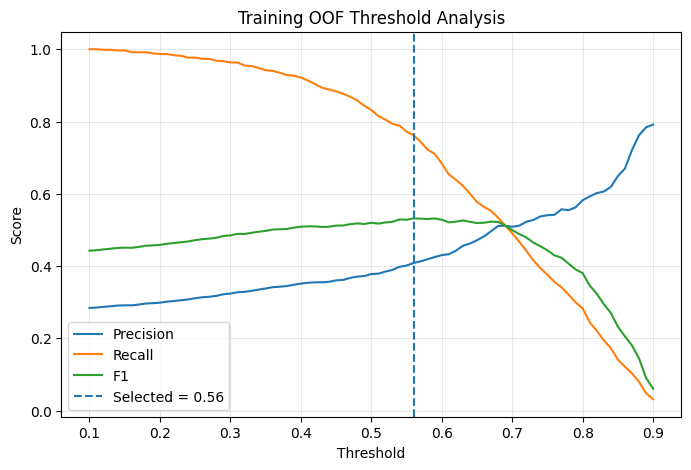

In [25]:
# ------------------ Stage 14: Threshold Selection ------------------

selected_model_name = max(
    searches, key=lambda name: searches[name].best_score_
)
selected_pipeline = optimized_pipelines[selected_model_name]

oof_probabilities = cross_val_predict(
    selected_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.01):
    pred = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_df.loc[threshold_df["F1"].idxmax(), "Threshold"]
)

print("Selected model:", selected_model_name)
print("Training OOF threshold:", round(best_threshold, 2))
display(threshold_df.loc[threshold_df["F1"].idxmax()].to_frame("Selected result"))

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1"], label="F1")
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Training OOF Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Stage 15: Final hold-out test evaluation

,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
Default threshold 0.50,0.5659,0.3679,0.78,0.5000,0.6873,0.2584
Training-selected threshold 0.56,0.6252,0.3984,0.68,0.5025,0.6873,0.2584



Classification report:
                            precision    recall  f1-score   support

Operational MASLD negative       0.83      0.60      0.70       389
Operational MASLD positive       0.40      0.68      0.50       150

                  accuracy                           0.63       539
                 macro avg       0.61      0.64      0.60       539
              weighted avg       0.71      0.63      0.64       539



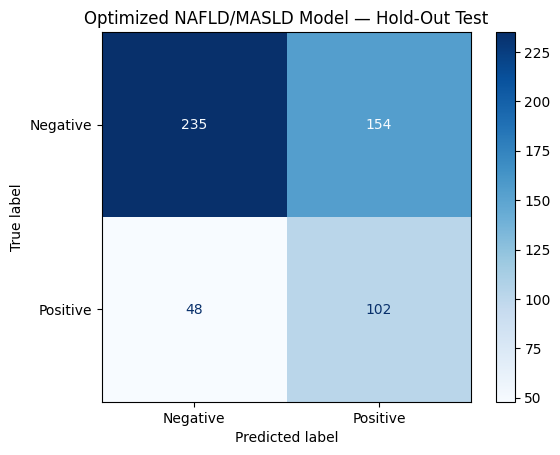

Confusion matrix:
[[235 154]
 [ 48 102]]


In [26]:
# ------------------ Stage 15: Final Test Evaluation ------------------

final_probabilities = selected_pipeline.predict_proba(X_test)[:, 1]

final_metrics = pd.DataFrame(
    [
        calculate_metrics(y_test, final_probabilities, threshold=0.50),
        calculate_metrics(y_test, final_probabilities, threshold=best_threshold)
    ],
    index=[
        "Default threshold 0.50",
        f"Training-selected threshold {best_threshold:.2f}"
    ]
)
display(final_metrics.round(4))

final_predictions = (final_probabilities >= best_threshold).astype(int)

print("\nClassification report:")
print(classification_report(
    y_test, final_predictions,
    target_names=["Operational MASLD negative", "Operational MASLD positive"],
    zero_division=0
))

cm = confusion_matrix(y_test, final_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues")
plt.title("Optimized NAFLD/MASLD Model — Hold-Out Test")
plt.show()

print("Confusion matrix:")
print(cm)

In [ ]:
# ------------------ Export: MASLD Final Metrics ------------------

final_metrics.to_csv("masld_final_metrics.csv", index=False)

from google.colab import files
files.download("masld_final_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 16: ROC and precision-recall curves

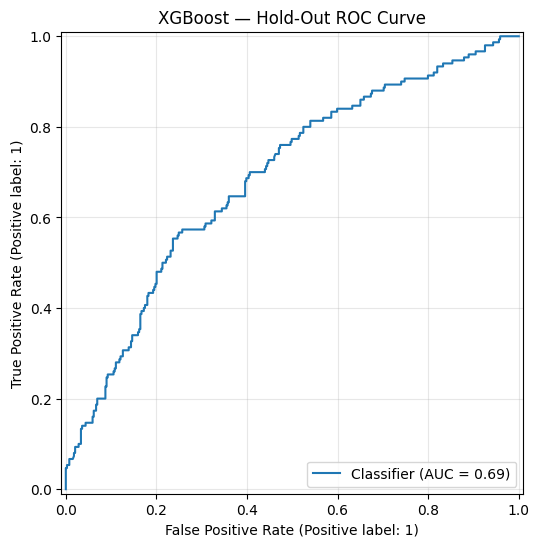

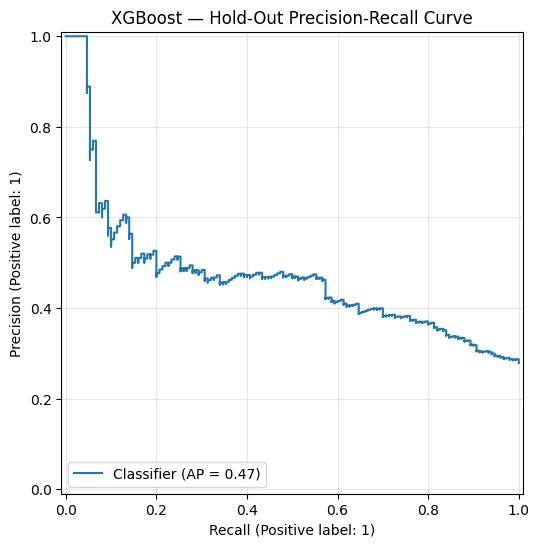

Average precision: 0.4685


In [27]:
# ------------------ Stage 16: Discrimination Curves ------------------

fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, final_probabilities, ax=ax)
ax.set_title(f"{selected_model_name} — Hold-Out ROC Curve")
ax.grid(alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(y_test, final_probabilities, ax=ax)
ax.set_title(f"{selected_model_name} — Hold-Out Precision-Recall Curve")
ax.grid(alpha=0.3)
plt.show()

print("Average precision:", round(
    average_precision_score(y_test, final_probabilities), 4
))

## Additional Experiment: XGBoost Hyperparameter Optimization

### Objective

The original XGBoost optimization improved recall but reduced accuracy and precision.

This experiment investigates whether alternative hyperparameter optimization objectives can provide a better balance between classification metrics.

Model selection will use training data and stratified cross-validation. The hold-out test set will remain reserved for final evaluation.

In [28]:
# ------------------ Additional Experiment: XGBoost Pipeline Inspection ------------------

xgb_pipeline = optimized_pipelines["XGBoost"]

print("XGBoost Pipeline:")
print(xgb_pipeline)

print("\nAvailable XGBoost Hyperparameters:")
for param in xgb_pipeline.get_params().keys():
    if param.startswith("classifier__"):
        print(param)

XGBoost Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['RIDAGEYR', 'LUXSMED']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                       

### Hyperparameter Optimization Strategy

Randomized Search CV is used to investigate alternative XGBoost configurations.

Three optimization objectives are compared:
- F1-score: balances precision and recall.
- Recall: prioritizes identifying positive cases.
- ROC-AUC: evaluates discrimination across classification thresholds.

All optimization is performed using training data and stratified 5-fold cross-validation. The hold-out test set remains untouched until final evaluation.

In [29]:
# ------------------ Additional Experiment: XGBoost Hyperparameter Optimization ------------------

from sklearn.model_selection import RandomizedSearchCV

xgb_param_distributions = {
    "classifier__n_estimators": [400, 600, 800, 1000],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.005, 0.01, 0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__gamma": [0, 0.1, 0.3, 0.5],
    "classifier__reg_alpha": [0, 0.01, 0.1, 1],
    "classifier__reg_lambda": [1, 2, 5, 10],
    "classifier__scale_pos_weight": [1, 2, 2.5, 3]
}

xgb_search = RandomizedSearchCV(
    estimator=optimized_pipelines["XGBoost"],
    param_distributions=xgb_param_distributions,
    n_iter=30,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc"
    },
    refit="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

xgb_search.fit(X_train, y_train)

print("XGBoost Hyperparameter Search Completed")

print("\nBest F1 CV Score:")
print(round(xgb_search.best_score_, 4))

print("\nBest Parameters (F1 Objective):")
print(xgb_search.best_params_)

xgb_cv_results = pd.DataFrame(xgb_search.cv_results_)

best_xgb_f1_index = xgb_cv_results["rank_test_f1"].idxmin()
best_xgb_recall_index = xgb_cv_results["rank_test_recall"].idxmin()
best_xgb_auc_index = xgb_cv_results["rank_test_roc_auc"].idxmin()

xgb_objective_comparison = pd.DataFrame([
    {
        "Objective": "F1",
        "Mean CV F1": xgb_cv_results.loc[best_xgb_f1_index, "mean_test_f1"],
        "Mean CV Recall": xgb_cv_results.loc[best_xgb_f1_index, "mean_test_recall"],
        "Mean CV ROC-AUC": xgb_cv_results.loc[best_xgb_f1_index, "mean_test_roc_auc"]
    },
    {
        "Objective": "Recall",
        "Mean CV F1": xgb_cv_results.loc[best_xgb_recall_index, "mean_test_f1"],
        "Mean CV Recall": xgb_cv_results.loc[best_xgb_recall_index, "mean_test_recall"],
        "Mean CV ROC-AUC": xgb_cv_results.loc[best_xgb_recall_index, "mean_test_roc_auc"]
    },
    {
        "Objective": "ROC-AUC",
        "Mean CV F1": xgb_cv_results.loc[best_xgb_auc_index, "mean_test_f1"],
        "Mean CV Recall": xgb_cv_results.loc[best_xgb_auc_index, "mean_test_recall"],
        "Mean CV ROC-AUC": xgb_cv_results.loc[best_xgb_auc_index, "mean_test_roc_auc"]
    }
])

print("\nComparison of Best Configurations by CV Objective:")
display(xgb_objective_comparison.round(4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
XGBoost Hyperparameter Search Completed

Best F1 CV Score:
0.5273

Best Parameters (F1 Objective):
{'classifier__subsample': 0.7, 'classifier__scale_pos_weight': 3, 'classifier__reg_lambda': 10, 'classifier__reg_alpha': 1, 'classifier__n_estimators': 400, 'classifier__min_child_weight': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.005, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}

Comparison of Best Configurations by CV Objective:


,Objective,Mean CV F1,Mean CV Recall,Mean CV ROC-AUC
0,F1,0.5273,0.7621,0.7325
1,Recall,0.5273,0.7621,0.7325
2,ROC-AUC,0.5140,0.5341,0.7355


### Hold-Out Test Evaluation

The best XGBoost configurations selected using F1-score, Recall, and ROC-AUC are evaluated on the same hold-out test set.

All configurations use a classification threshold of 0.50 for this comparison.

The objective is to examine whether improvements observed during cross-validation translate into better performance on unseen data.

In [30]:
# ------------------ Additional Experiment: XGBoost Hold-Out Test Evaluation ------------------

from sklearn.base import clone

xgb_objective_models = {
    "F1 Optimized": xgb_search.best_estimator_,

    "Recall Optimized": clone(
        optimized_pipelines["XGBoost"]
    ).set_params(
        **xgb_cv_results.loc[best_xgb_recall_index, "params"]
    ),

    "ROC-AUC Optimized": clone(
        optimized_pipelines["XGBoost"]
    ).set_params(
        **xgb_cv_results.loc[best_xgb_auc_index, "params"]
    )
}

xgb_objective_test_rows = []

for model_name, model in xgb_objective_models.items():

    if model_name != "F1 Optimized":
        model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    xgb_objective_test_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Brier Score": brier_score_loss(y_test, probabilities)
    })

xgb_objective_test_df = pd.DataFrame(xgb_objective_test_rows)

print("XGBoost: Hold-Out Test Comparison")
display(xgb_objective_test_df.round(4))

XGBoost: Hold-Out Test Comparison


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Brier Score
0,F1 Optimized,0.6160,0.3941,0.7067,0.5060,0.6839,0.2309
1,Recall Optimized,0.6160,0.3941,0.7067,0.5060,0.6839,0.2309
2,ROC-AUC Optimized,0.7199,0.4966,0.4800,0.4881,0.6872,0.2014


### Final Comparison: XGBoost Optimization Experiments

This comparison summarizes the original optimized XGBoost model and the additional configurations selected using F1-score, Recall, and ROC-AUC.

The purpose is to evaluate the effect of different optimization objectives on hold-out test performance.

In [31]:
# ------------------ Additional Experiment: Final XGBoost Comparison ------------------

xgb_final_comparison = pd.DataFrame([
    {
        "Model": "Original Optimized XGBoost",
        "Accuracy": 0.5659,
        "Precision": 0.3679,
        "Recall": 0.7800,
        "F1": 0.5000,
        "ROC-AUC": 0.6873
    },
    *[
        {
            "Model": row["Model"],
            "Accuracy": row["Accuracy"],
            "Precision": row["Precision"],
            "Recall": row["Recall"],
            "F1": row["F1"],
            "ROC-AUC": row["ROC-AUC"]
        }
        for _, row in xgb_objective_test_df.iterrows()
    ]
])

display(xgb_final_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Original Optimized XGBoost,0.5659,0.3679,0.7800,0.5000,0.6873
1,F1 Optimized,0.6160,0.3941,0.7067,0.5060,0.6839
2,Recall Optimized,0.6160,0.3941,0.7067,0.5060,0.6839
3,ROC-AUC Optimized,0.7199,0.4966,0.4800,0.4881,0.6872


## Stage 17: Probability calibration

,Model,Brier Score,ROC-AUC
0,Uncalibrated,0.2584,0.6873
1,Sigmoid calibrated,0.1841,0.6884


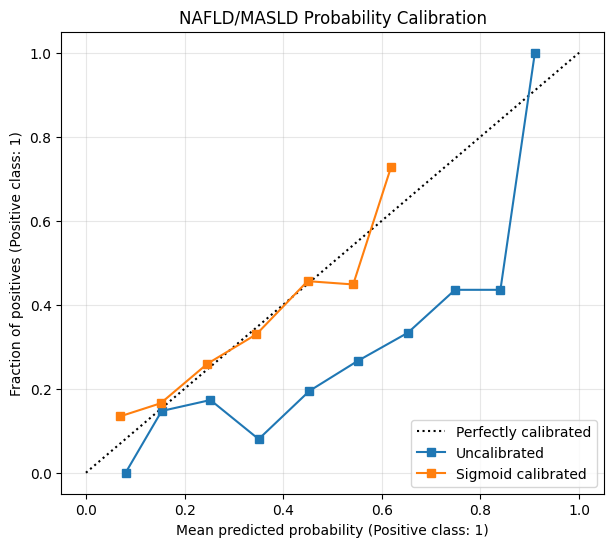

In [ ]:
# ------------------ Stage 17: Calibration Assessment ------------------

calibrated_model = CalibratedClassifierCV(
    estimator=selected_pipeline,
    method="sigmoid",
    cv=cv
)
calibrated_model.fit(X_train, y_train)

calibrated_probabilities = calibrated_model.predict_proba(X_test)[:, 1]

calibration_results = pd.DataFrame({
    "Model": ["Uncalibrated", "Sigmoid calibrated"],
    "Brier Score": [
        brier_score_loss(y_test, final_probabilities),
        brier_score_loss(y_test, calibrated_probabilities)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, final_probabilities),
        roc_auc_score(y_test, calibrated_probabilities)
    ]
})
display(calibration_results.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_test, final_probabilities, n_bins=10,
    name="Uncalibrated", ax=ax
)
CalibrationDisplay.from_predictions(
    y_test, calibrated_probabilities, n_bins=10,
    name="Sigmoid calibrated", ax=ax
)
ax.set_title("NAFLD/MASLD Probability Calibration")
ax.grid(alpha=0.3)
plt.show()

In [ ]:
# ------------------ Export: MASLD Calibration Results ------------------

calibration_results.to_csv("masld_calibration_results.csv", index=False)

from google.colab import files
files.download("masld_calibration_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Stage 18: Save optimized artifacts

In [ ]:
# ------------------ Stage 18: Save Optimized Model ------------------

joblib.dump(
    calibrated_model,
    "masld_optimized_calibrated_pipeline.pkl"
)
joblib.dump(
    selected_pipeline,
    "masld_optimized_pipeline.pkl"
)

metadata = {
    "target": "MASLD",
    "target_definition": (
        "Operational label: CAP >= 302 dB/m plus at least one "
        "cardiometabolic risk indicator, subject to approximate alcohol eligibility"
    ),
    "selected_model": selected_model_name,
    "training_selected_threshold": best_threshold,
    "features": list(X_train.columns),
    "random_state": RANDOM_STATE
}
joblib.dump(metadata, "masld_optimized_metadata.pkl")

print("Saved:")
print("- masld_optimized_calibrated_pipeline.pkl")
print("- masld_optimized_pipeline.pkl")
print("- masld_optimized_metadata.pkl")

Saved:
- masld_optimized_calibrated_pipeline.pkl
- masld_optimized_pipeline.pkl
- masld_optimized_metadata.pkl



# Stage 19: Final Summary and Key Findings

## 1. Dataset and Target Overview

- **Dataset:** NHANES 2017–2018.
- **Labelled participants:** 2,694.
- **Target:** Operational MASLD classification based on CAP-defined hepatic steatosis, alcohol eligibility, and cardiometabolic risk indicators.
- **Class distribution:** 1,943 negative and 751 positive participants.

## 2. Baseline vs Optimized Model Performance

| Model | Version | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---:|---:|---:|---:|---:|
| Logistic Regression | Baseline | 0.6475 | 0.4020 | 0.5467 | 0.4633 | 0.6468 |
| Logistic Regression | Optimized | 0.6475 | 0.4020 | 0.5467 | 0.4633 | 0.6472 |
| Random Forest | Baseline | 0.6642 | 0.3578 | 0.2600 | 0.3012 | 0.5956 |
| Random Forest | Optimized | 0.7161 | 0.4717 | 0.1667 | 0.2463 | 0.6797 |
| XGBoost | Baseline | 0.7087 | 0.4521 | 0.2200 | 0.2960 | 0.6556 |
| XGBoost | Optimized | 0.5659 | 0.3679 | 0.7800 | 0.5000 | 0.6873 |

**Key Findings:**
- Optimized XGBoost achieved the highest recall and F1-score among the original optimized models.
- Random Forest achieved the highest optimized accuracy and precision.
- Logistic Regression showed almost unchanged classification performance after optimization.
- XGBoost was selected based on its highest cross-validation ROC-AUC of 0.7355.

## 3. Selected Model and Classification Threshold

- **Selected model:** Optimized XGBoost.
- **Selection criterion:** Highest cross-validation ROC-AUC (0.7355).
- **Selected threshold:** 0.56.
- **Threshold selection method:** Maximum F1-score using training out-of-fold predictions.
- The hold-out test set was not used to select the threshold.

## 4. Final Hold-Out Test Evaluation

| Metric | Threshold 0.50 | Threshold 0.56 |
|---|---:|---:|
| Accuracy | 0.5659 | 0.6252 |
| Precision | 0.3679 | 0.3984 |
| Recall | 0.7800 | 0.6800 |
| F1-score | 0.5000 | 0.5025 |
| ROC-AUC | 0.6873 | 0.6873 |

**Confusion Matrix at Threshold 0.56:**

| | Predicted Negative | Predicted Positive |
|---|---:|---:|
| Actual Negative | 235 | 154 |
| Actual Positive | 48 | 102 |

**Key Findings:**
- Accuracy and precision improved at threshold 0.56.
- Recall decreased from 78% to 68%.
- F1-score improved slightly from 0.5000 to 0.5025.
- ROC-AUC remained unchanged because threshold adjustment does not change predicted probabilities.

## 5. Feature Ablation Analysis

| Feature Set | CV ROC-AUC | Test ROC-AUC |
|---|---:|---:|
| Demographics + Liver Stiffness | 0.7348 | 0.6872 |
| Demographics Only | 0.6345 | 0.6114 |

**Key Findings:**
- Removing liver stiffness reduced model performance.
- LUXSMED contributed useful predictive information.
- LUXSMED is measured during the same examination as CAP and may act as a proxy; its contribution requires further validation.

## 6. Probability Calibration

| Model | Brier Score | ROC-AUC |
|---|---:|---:|
| Uncalibrated XGBoost | 0.2584 | 0.6873 |
| Sigmoid Calibrated XGBoost | 0.1841 | 0.6884 |

**Key Findings:**
- Sigmoid calibration reduced the Brier score from 0.2584 to 0.1841.
- Relative Brier score reduction was approximately 28.75%.
- ROC-AUC remained nearly unchanged.
- Independent validation is required to confirm calibration performance.

## 7. Additional XGBoost Optimization Investigation

Alternative hyperparameter optimization objectives were investigated using F1-score, recall, and ROC-AUC.

- F1-optimized XGBoost achieved a test F1-score of 0.5060 and accuracy of 0.6160.
- ROC-AUC-optimized XGBoost achieved the highest accuracy (0.7199) and precision (0.4966) among the additional configurations.
- The original optimized XGBoost retained the highest recall (0.7800).
- These additional experiments demonstrated different precision-recall trade-offs but did not replace the originally selected model.

## 8. Limitations

- The target represents an operational MASLD classification, not a clinically confirmed diagnosis.
- Alcohol eligibility was estimated approximately.
- Cardiometabolic indicators used simplified thresholds.
- Fasting glucose and triglyceride measurements were available only for subsamples.
- NHANES survey weights were not incorporated; therefore, results are not nationally representative estimates.
- LUXSMED may introduce same-examination proxy information.
- Model comparisons rely on a single hold-out split.
- Independent external validation is required before clinical application.

## 9. Conclusion

- The study developed and evaluated Logistic Regression, Random Forest, and XGBoost models for operational MASLD classification using NHANES 2017–2018 data.
- Optimized XGBoost was selected based on the highest cross-validation ROC-AUC of 0.7355.
- At the training-selected threshold of 0.56, the model achieved a test ROC-AUC of 0.6873 and an F1-score of 0.5025.
- Sigmoid calibration improved probability reliability by reducing the Brier score from 0.2584 to 0.1841.
- Additional optimization experiments demonstrated different trade-offs between accuracy, precision, and recall.
- The results indicate limited predictive discrimination and provide a foundation for further research; however, external validation is necessary before considering clinical applications.
